# Customer Analytics for an Indian D2C Beauty Brand
RFM segmentation · cohort retention · K-means · COD/RTO economics · LTV:CAC · predictive CLV

> Synthetic data (`src/generate_data.py`, seed 21): 60K customers, 120K orders, Jan-2024 to Dec-2025.

In [1]:
import sys
import warnings

sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display

import charts
from analytics import *

pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
customers, orders, cac = load()
orders.head()

,order_id,customer_id,order_date,order_seq,category,items,sale_event,payment_mode,status,gross_value,discount,net_value,shipping_fee_charged
0,O0000001,C000024,2024-01-01,1,Makeup,1,NaN,UPI,Delivered,590.0,118.0,472.0,49
1,O0000002,C000459,2024-01-01,1,Fragrance,1,NaN,UPI,Returned,1510.0,302.0,1208.0,0
2,O0000003,C000860,2024-01-01,1,Bath & Body,1,NaN,COD,Delivered,510.0,102.0,408.0,49
3,O0000004,C002322,2024-01-01,1,Skincare,1,NaN,UPI,Delivered,490.0,98.0,392.0,49
4,O0000005,C002941,2024-01-01,1,Bath & Body,3,NaN,UPI,Delivered,580.0,116.0,464.0,49


## 1. Business overview

In [2]:
k = kpi_summary(customers, orders)
print('Customers with 2+ orders:', k.attrs['repeat_rate_pct'], '%')
k

Customers with 2+ orders: 42.0 %


,orders,delivered_revenue_cr,aov,active_customers,new_customers,rto_rate_pct,cod_share_pct,contribution_cr
year,,,,,,,,
2024,45441,2.88,747.71,25445,25445,10.52,37.34,1.52
2025,74939,4.84,755.94,39205,34555,9.68,35.18,2.58


## 2. Cohort retention
Each row is the month of a customer's first order; cells show % ordering again N months later.

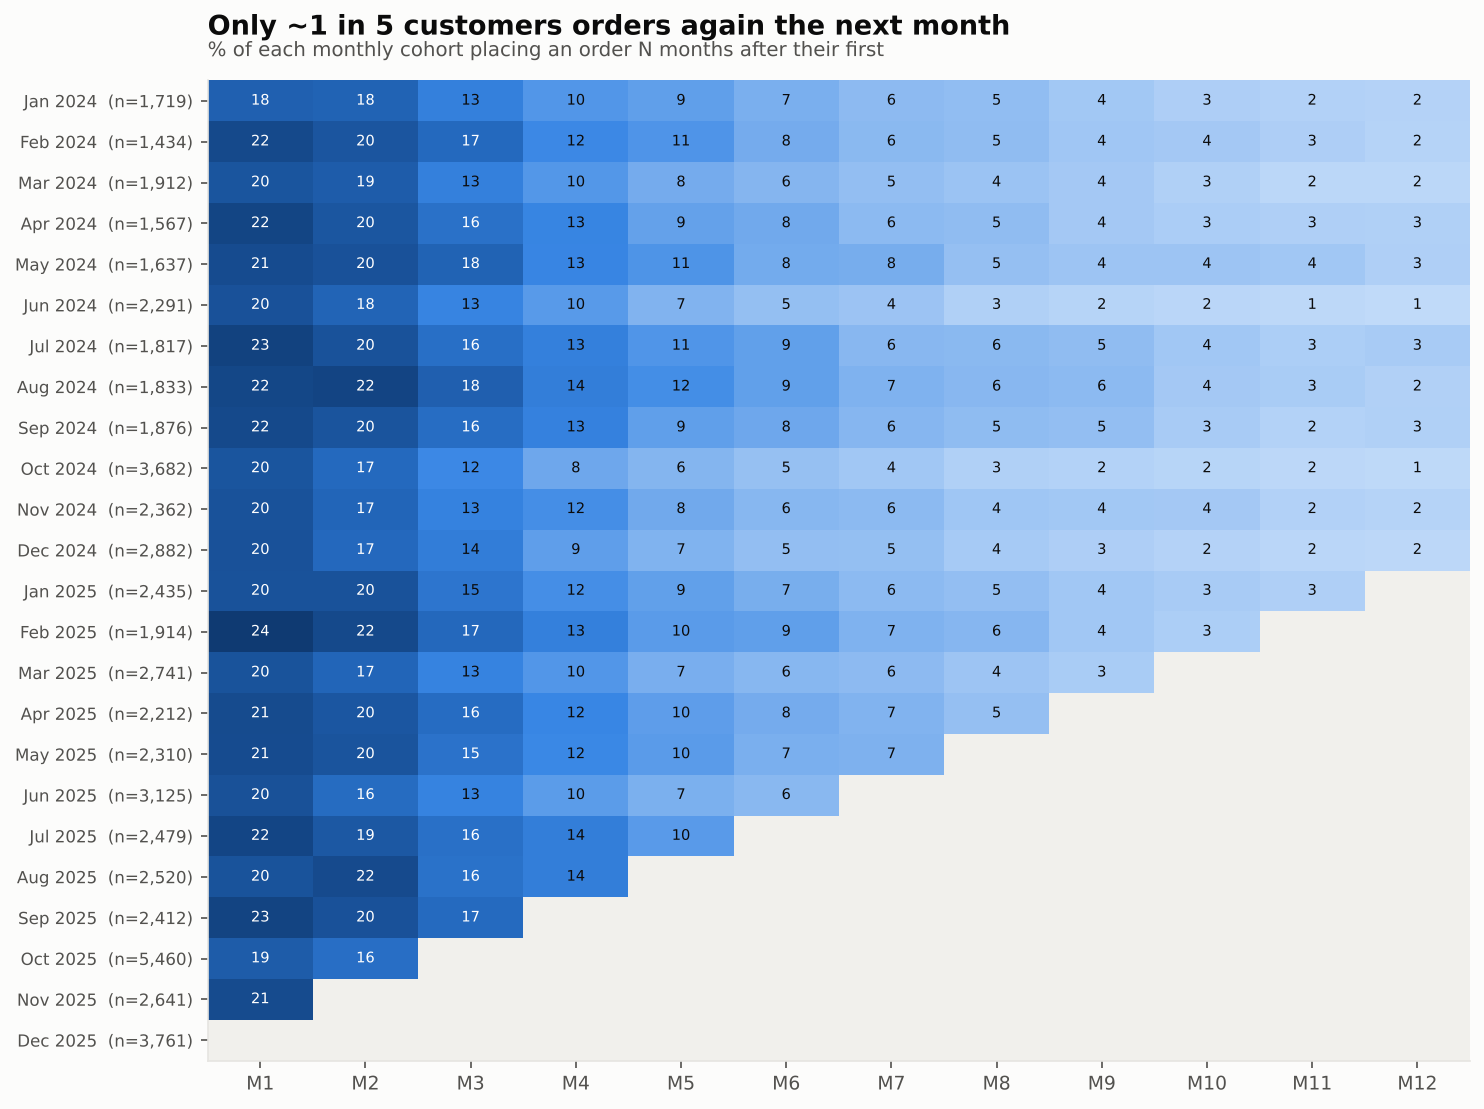

In [3]:
cm = cohort_matrix(orders)
charts.cohort_heatmap(cm)
display(Image('../images/cohort_heatmap.png'))

### Do sale-acquired customers stick?

,repeat_1m_pct,repeat_3m_pct,repeat_6m_pct,repeat_12m_pct
full price,17.4,42.5,48.8,50.0
in a sale,15.6,32.5,35.4,35.5


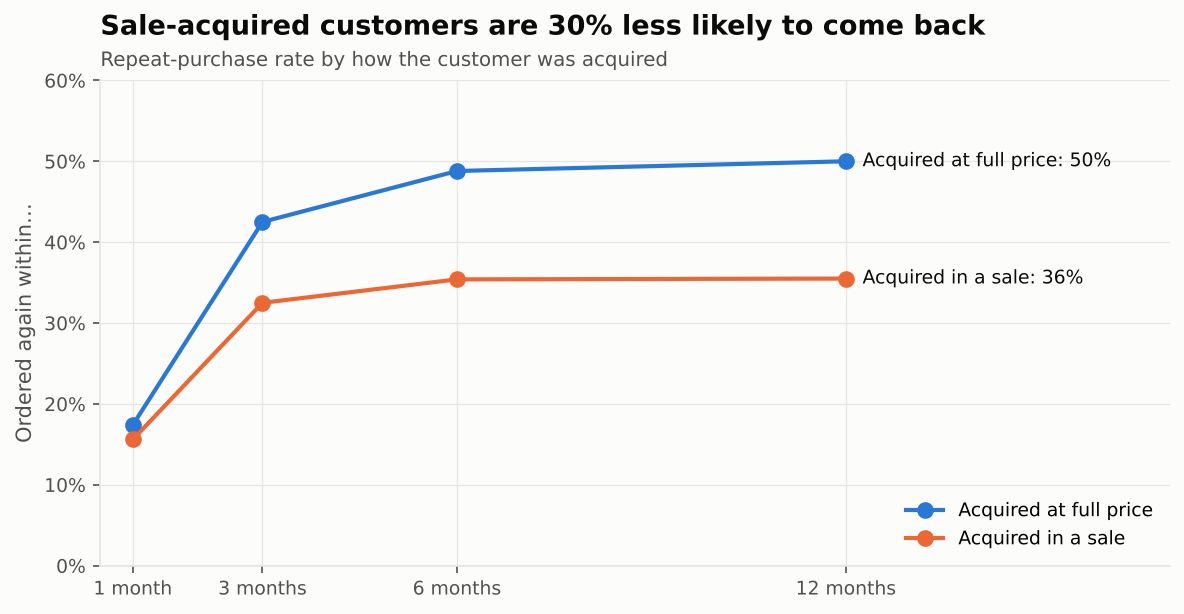

In [4]:
ret_sale = retention_by_group(orders, customers, 'acquired_in_sale')
charts.sale_vs_fullprice(ret_sale)
display(ret_sale.rename(index={0: 'full price', 1: 'in a sale'}))
display(Image('../images/sale_vs_fullprice_retention.png'))

In [5]:
retention_by_group(orders, customers, 'acquisition_channel').sort_values('repeat_6m_pct', ascending=False)

,repeat_1m_pct,repeat_3m_pct,repeat_6m_pct,repeat_12m_pct
Referral,19.2,49.8,58.9,59.7
Organic / Direct,19.0,49.2,57.2,59.1
Google Search,17.6,45.6,52.9,53.9
Marketplace Insert,16.8,38.9,43.4,43.9
Instagram Ads,15.7,34.3,36.9,36.5
Influencer,14.0,27.9,28.5,28.0


## 3. RFM segmentation and action playbook
Recency and monetary are scored on quintiles. Frequency uses fixed thresholds (1 / 2 / 3 / 4-5 / 6+ orders) because most customers have exactly one order, which breaks quintiles.

,customers,avg_recency_days,avg_orders,avg_spend,customer_pct,revenue_pct,action
segment,,,,,,,
Champions,3267,64.4,5.9,4467.5,6.5,19.3,"Early access to launches, referral programme, ..."
Loyal,4725,160.3,3.8,2817.8,9.4,17.6,Bundles and subscriptions (skincare replenishm...
Potential Loyalist,4295,65.6,2.0,1462.2,8.5,8.3,Second-purchase nudge at day 30-45 with a cros...
New,10436,65.8,1.0,739.0,20.7,10.2,"Onboarding series: how-to content, review requ..."
At Risk,6873,401.7,2.0,1500.0,13.6,13.6,Win-back: personalised offer on their last cat...
Can't Lose Them,3204,445.3,4.0,3109.4,6.4,13.1,"High-value lapsed: call / WhatsApp from CX, st..."
Hibernating,17589,419.8,1.0,773.4,34.9,18.0,"Low-cost channels only (email, WhatsApp broadc..."


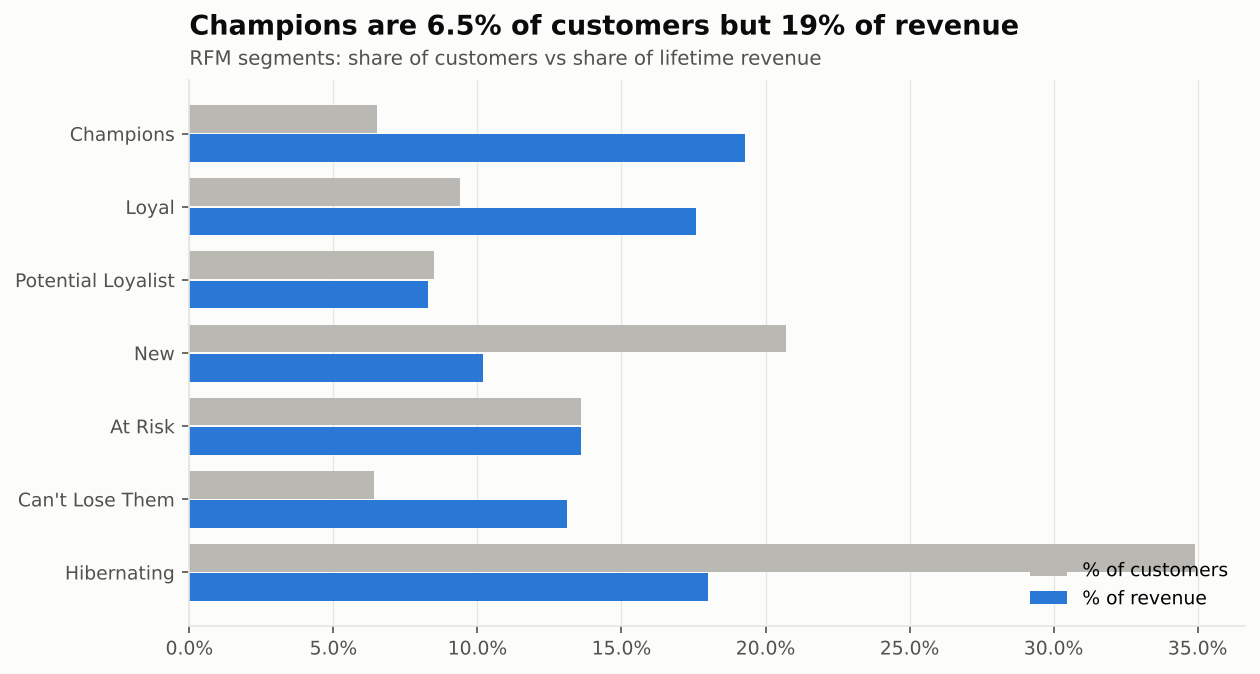

In [6]:
r = rfm(orders)
seg = segment_summary(r)
charts.segment_chart(seg)
display(seg)
display(Image('../images/rfm_segments.png'))

In [7]:
# export the CRM target list
r.reset_index().to_csv('../reports/rfm_customer_segments.csv', index=False)
seg.to_csv('../reports/segment_playbook.csv')
r.segment.value_counts()

segment
Hibernating           17589
New                   10436
At Risk                6873
Loyal                  4725
Potential Loyalist     4295
Champions              3267
Can't Lose Them        3204
Name: count, dtype: int64

### Does unsupervised clustering agree?
K-means on log-scaled, standardised R/F/M; k chosen by silhouette score.

In [8]:
sil, prof, labels = kmeans_segments(r)
display(sil.to_frame())
display(prof)
pd.crosstab(r.segment, labels, normalize='index').round(2)

,silhouette
3,0.383
4,0.356
5,0.351
6,0.339
7,0.324


,customers,recency_days,orders,spend
cluster,,,,
1,13170,207.0,4.1,3285.0
2,11271,40.0,1.3,909.8
0,25948,375.0,1.2,857.9


col_0,0,1,2
segment,,,
At Risk,0.76,0.24,0.00
Can't Lose Them,0.00,1.00,0.00
Champions,0.00,0.99,0.01
Hibernating,1.00,0.00,0.00
Loyal,0.01,0.89,0.10
New,0.24,0.00,0.76
Potential Loyalist,0.14,0.20,0.66


## 4. Cash-on-Delivery and RTO
RTO = parcel refused at the door and shipped back. The brand pays shipping both ways and earns nothing.

,cod_share_pct,rto_rate_pct_COD,rto_rate_pct_Prepaid
city_tier,,,
Metro,21.9,18.0,1.6
Tier 1,33.6,21.9,2.1
Tier 2,49.8,26.0,2.2
Tier 3,62.3,31.8,3.3


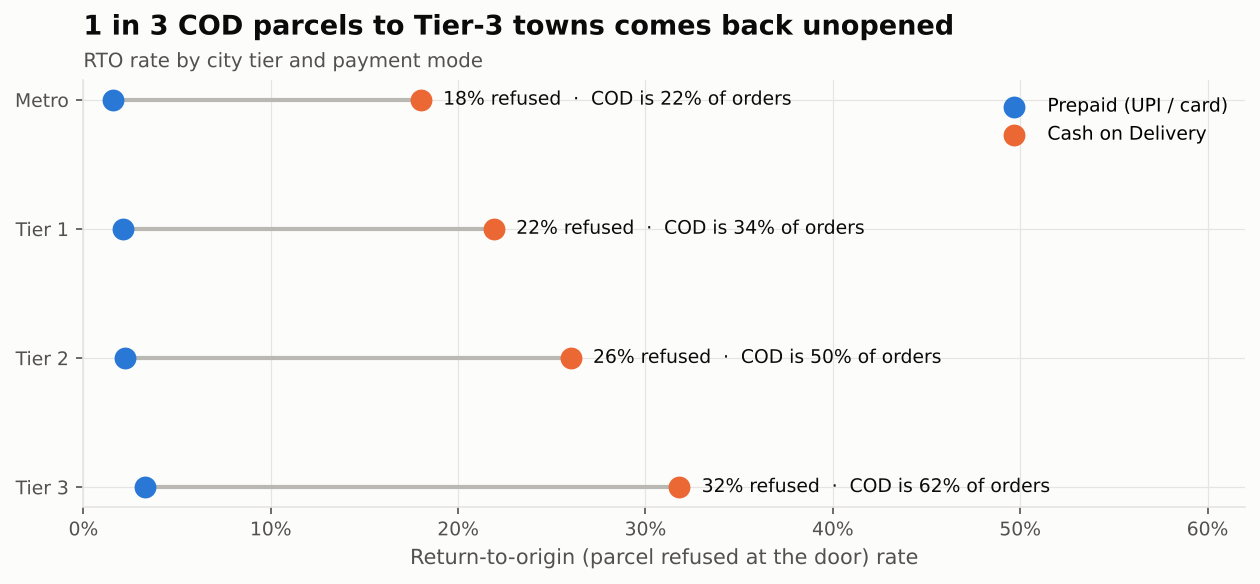

In [9]:
t = rto_analysis(orders, customers)
charts.rto_chart(t)
display(t)
display(Image('../images/rto_by_tier.png'))

In [10]:
# Scenario: Rs 40 off for paying online shifts 30% of COD orders to prepaid
prepaid_nudge_scenario(orders, shift=0.30, incentive=40)

{'cod_orders_2025': 26361,
 'orders_shifted': 7908,
 'rto_avoided': 1733,
 'rto_rate_cod_pct': 23.9,
 'rto_rate_prepaid_pct': 2.0,
 'logistics_saving_lakh': 4.0,
 'recovered_margin_lakh': 7.1,
 'incentive_cost_lakh': 3.1,
 'net_benefit_lakh': 7.9}

In [11]:
pd.DataFrame([prepaid_nudge_scenario(orders, shift=s, incentive=i) for s in (0.15, 0.3, 0.45) for i in (25, 40, 60)])[['orders_shifted', 'rto_avoided', 'incentive_cost_lakh', 'net_benefit_lakh']].set_index(pd.MultiIndex.from_product([[0.15, 0.3, 0.45], [25, 40, 60]], names=['shift', 'incentive_rs']))

orders_shifted  rto_avoided  incentive_cost_lakh  net_benefit_lakh
shift incentive_rs                                                                    
0.15  25                      3954          866                  1.0               4.5
      40                      3954          866                  1.6               4.0
      60                      3954          866                  2.3               3.2
0.30  25                      7908         1733                  1.9               9.1
      40                      7908         1733                  3.1               7.9
      60                      7908         1733                  4.7               6.4
0.45  25                     11862         2599                  2.9              13.6
      40                     11862         2599                  4.7              11.9
      60                     11862         2599                  7.0               9.6

## 5. LTV:CAC by acquisition channel
CAC values are planning assumptions (`data/raw/channel_cac.csv`). LTV = 12-month contribution margin after product cost, shipping, COD fees, RTO and returns.

,ltv_12m_contribution,customers,cac_inr,ltv_to_cac,payback
acquisition_channel,,,,,
Organic / Direct,1028.78,5254,90,11.43,within 12 months
Referral,1101.53,2054,180,6.12,within 12 months
Marketplace Insert,602.23,3503,150,4.01,within 12 months
Google Search,913.64,4413,260,3.51,within 12 months
Instagram Ads,558.72,6693,420,1.33,within 12 months
Influencer,572.61,3528,650,0.88,not paid back


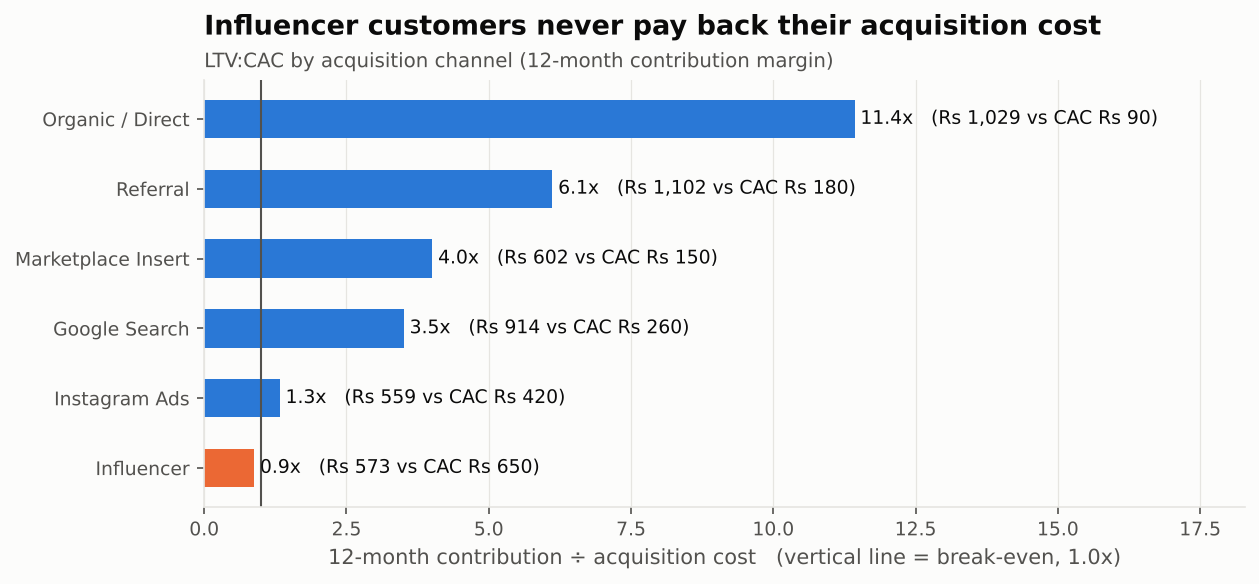

In [12]:
ltv = ltv_by_channel(orders, customers, cac)
charts.ltv_cac_chart(ltv)
display(ltv)
display(Image('../images/ltv_cac.png'))

## 6. Predictive CLV
Features from each customer's **first 90 days**. Target is delivered spend in the **next 180 days**. This is useful for deciding, early, who deserves retention spend.

{'r2': 0.214,
 'r2_naive_baseline': 0.114,
 'top20_capture_pct': 59.2,
 'top20_capture_naive_pct': 49.0,
 'test_customers': 9902}

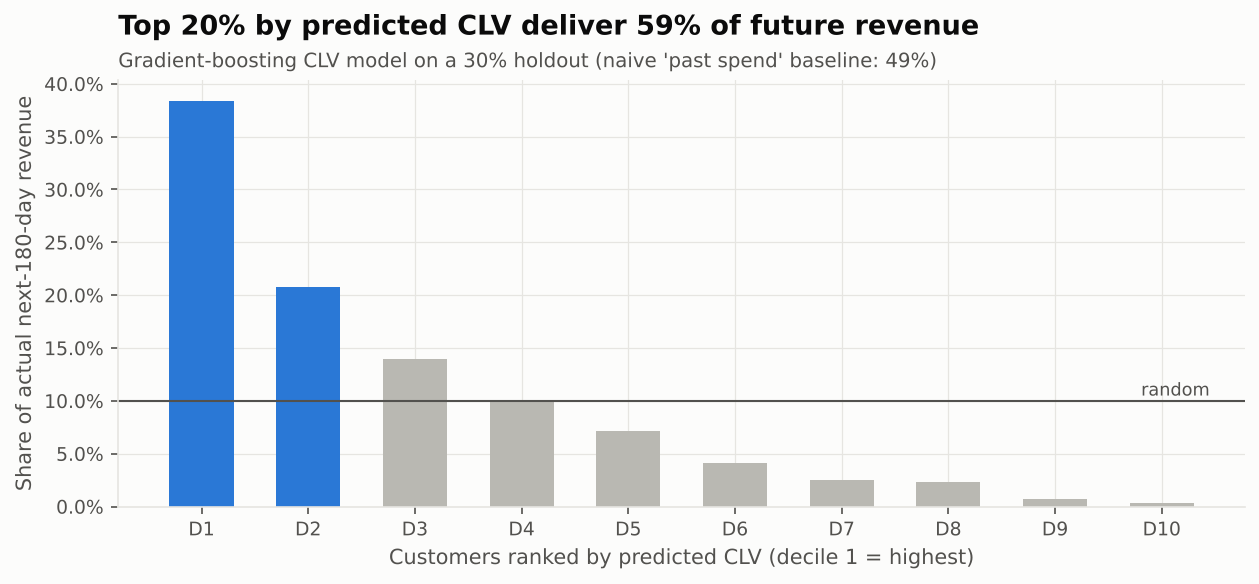

In [13]:
X, y = clv_features(orders, customers)
model, metrics, lift = train_clv_model(X, y)
charts.clv_lift_chart(lift, metrics)
display(metrics)
display(Image('../images/clv_model_lift.png'))

## 7. Replenishment timing
When should the 'running low?' reminder go out? Days between consecutive orders, by first category.

In [14]:
inter_purchase_days(orders)

,count,p25_days,median_days,p75_days
first_category,,,,
Skincare,23223.0,19.0,34.0,56.0
Haircare,10851.0,22.0,38.0,63.0
Bath & Body,5624.0,24.0,42.0,69.0
Makeup,6789.0,27.0,47.0,77.0
Fragrance,2300.0,29.0,51.0,85.0
Gift Sets,1478.0,27.0,52.0,90.0


## Recommendations
See the README for the summary table.